In [ ]:
import cv2
import numpy as np
import json
import os
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from scipy.stats import mode

def find_contour(mask, debug=False):
    # find all contours
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if debug:
        print(f"  Found {len(contours)} contour(s)")
    assert len(contours) > 0, "No contours found — boundary detection failed."

    # get largest contour and fill it in
    largest_contour = max(contours, key=cv2.contourArea)
    filled_mask = np.zeros_like(mask)
    cv2.drawContours(filled_mask, [largest_contour], -1, 255, thickness=cv2.FILLED)

    contour_line = np.zeros_like(mask)
    cv2.drawContours(contour_line, [largest_contour], -1, 255, thickness=2)
    
    if debug:
        # draw contour on img
        if len(mask.shape) == 2:
            outline = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)
        else:
            outline = mask.copy()
        cv2.drawContours(outline, [largest_contour], -1, (0, 0, 255), 2)

        cv2.imshow("Original", mask)
        cv2.imshow("Boundary mask (raw)", mask)
        cv2.imshow("Largest Contour Filled Mask", filled_mask)
        cv2.imshow("Largest Contour Outlined", outline)
        cv2.waitKey(0)
        cv2.destroyAllWindows()

    return contour_line, filled_mask

def kmeans_segment(img, features, k=2, r=10):
    h, w = img.shape[:2]

    kmeans = KMeans(n_clusters=k, random_state=0)
    kmeans.fit(features)
    labels = kmeans.labels_.reshape(h, w)

    # Find majority label in rxr center
    cx, cy = w // 2, h // 2
    roi = labels[cy - r:cy + r, cx - r:cx + r]

    m = mode(roi.flatten(), keepdims=False).mode
    majority_label = int(m)

    binary = np.uint8(labels == majority_label) * 255
    return labels, binary, majority_label


def segment_hsv(img, select_hsv="HSV", output_file=None, debug=False):
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # --- Pre-filtering ---
    img_blur = cv2.GaussianBlur(img, (5, 5), 0)
    img_blur = cv2.medianBlur(img_blur, 5)

    h, w = img_blur.shape[:2]
    rgb = img_blur.reshape(-1, 3)

    # HSV feature set
    hsv_img = cv2.cvtColor(img_blur, cv2.COLOR_RGB2HSV)
    hsv = hsv_img.reshape(-1, 3)
    
    if select_hsv == "H":
        hsv_selected = hsv[:, [0]]
    elif select_hsv == "S":
        hsv_selected = hsv[:, [1]]
    elif select_hsv == "V":
        hsv_selected = hsv[:, [2]]
    else:
        hsv_selected = hsv

    # RGB + HSV kmeans
    rgb_hsv = np.column_stack((rgb, hsv_selected))
    labels, mask, maj_labels = kmeans_segment(
        img_blur, rgb_hsv, k=2
    )
    # close holes
    # kernel = np.ones((morph_close, morph_close), np.uint8)
    # mask_clean = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    
    if debug:
        cv2.imshow("Mask via Kmeans with seHSVlect", mask)
        cv2.waitKey(0)
        cv2.destroyAllWindows()

    return mask

def segment_saturation(img, thresh_adjust:int=0, debug=False):
    hsv_image = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    saturation = hsv_image[:, :, 1]
    otsu_thresh, binary = cv2.threshold(saturation, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    manual_thresh = np.clip(otsu_thresh + thresh_adjust, 0, 255)
    _, binary = cv2.threshold(saturation, manual_thresh, 255, cv2.THRESH_BINARY)
    
    if debug:
        fig, axes = plt.subplots(ncols=3, figsize=(12, 4))
        ax = axes.ravel()
        
        ax[0].imshow(saturation, cmap='gray')
        ax[0].set_title('Saturation Channel')
        ax[0].axis('off')
        
        ax[1].hist(saturation.ravel(), bins=256)
        ax[1].axvline(_, color='r', linestyle='--')  # Threshold value
        ax[1].set_title('Histogram')
        
        ax[2].imshow(binary, cmap='gray')
        ax[2].set_title('Thresholded')
        ax[2].axis('off')
        
        plt.tight_layout()
        plt.show()
    return binary

def segment_otsu(gray_img, thresh_adjust:int=0, debug=False):
    gray_image = img[:, :, 1]
    otsu_thresh, binary = cv2.threshold(gray_image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    manual_thresh = int(np.clip(otsu_thresh + thresh_adjust, 0, 255))
     # Decide inversion automatically (light background)
    invert = True#gray_img.mean() > manual_thresh
    thresh_type = cv2.THRESH_BINARY_INV if invert else cv2.THRESH_BINARY

    _, binary = cv2.threshold(gray_image, manual_thresh, 255, thresh_type)
    
    if debug:
        fig, axes = plt.subplots(ncols=3, figsize=(12, 4))
        ax = axes.ravel()
        
        ax[0].imshow(gray_image, cmap='gray')
        ax[0].set_title('Saturation Channel')
        ax[0].axis('off')
        
        ax[1].hist(gray_image.ravel(), bins=256)
        ax[1].axvline(_, color='r', linestyle='--')  # Threshold value
        ax[1].set_title('Histogram')
        
        ax[2].imshow(binary, cmap='gray')
        ax[2].set_title('Thresholded')
        ax[2].axis('off')
        
        plt.tight_layout()
        plt.show()
    return binary

def process_single(img, method="color", thresh_adjust=0, debug=True):
    if method=="saturation":
        segmented = segment_saturation(img, thresh_adjust, debug=debug)
    elif method=="kmeans":
        segmented = segment_hsv(img, debug=debug)
    elif method=="otsu":
        segmented = segment_otsu(img, thresh_adjust=60, debug=debug)
    else:
        print("invalid method")
        return
    if debug:
        cv2.imshow("new mask", segmented)
        # cv2.imwrite("mask.png",mask)
        cv2.waitKey(0)
        cv2.destroyAllWindows()

    contour_line, mask = find_contour(segmented)

    if debug:
        cv2.imshow("new mask", mask)
        cv2.imwrite("mask.png",mask)
        cv2.waitKey(0)
        cv2.destroyAllWindows()

    # Extract object
    result = cv2.bitwise_and(img, img, mask=mask)
    if debug:
        cv2.imshow("Segmented object", result)
        # cv2.imwrite("segmented.png",result)
        cv2.waitKey(0)
        cv2.destroyAllWindows()

if __name__ == "__main__":
    # img_file = "./image_stitching/data/mma_krater/Screenshot 2025-12-11 at 5.25.52 PM.png"
    # img_file = "./image_stitching/data/heidelberg/1.png"
    img_file = "./facsimile/data/test30_imgs/original-1-7.JPG"
    img = cv2.imread(img_file)
    # print(img)
    process_single(img, method="saturation", thresh_adjust=-10, debug=True)

# Actual Jupyter NB Processer

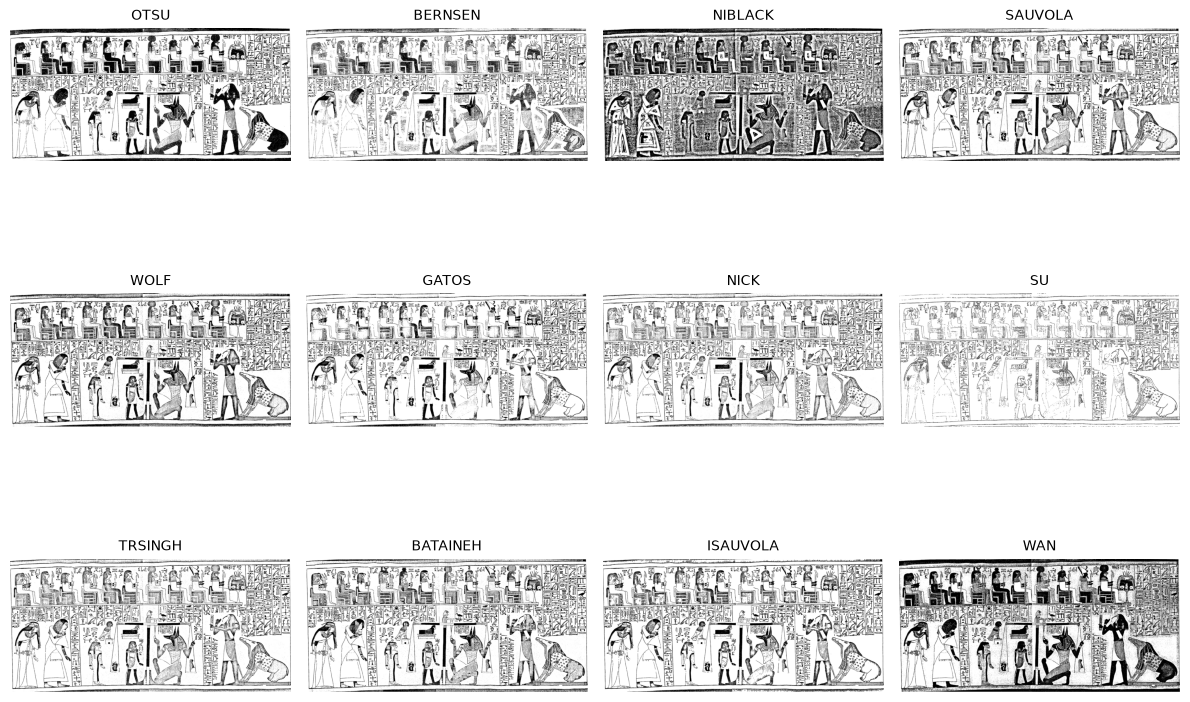

In [3]:
from skimage import data
from matplotlib import pyplot as plt
import skimage
import cv2
import numpy as np
# https://pypi.org/project/doxapy/
import doxapy
algorithms = ['OTSU', 'BERNSEN', 'NIBLACK', 'SAUVOLA', 'WOLF', 'GATOS', 'NICK', 'SU', 'TRSINGH', 'BATAINEH', 'ISAUVOLA', 'WAN']

def all_binarize_algos(img: np.ndarray):
    # Turn transparent parts of PNGs white
    if img.ndim == 3 and img.shape[2] == 4:
        alpha = img[:, :, 3]
        bgr = img[:, :, :3]

        white = np.full_like(bgr, 255)
        img = np.where(alpha[:, :, None] == 0, white, bgr)

    # Convert to flat 2D grayscale, no alpha (doxapy requires single-channel input)
    if img.ndim == 3:
        gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    else:
        gray_img = img
    all_bins = []
    for algo in algorithms:
        binary_image = np.empty(gray_img.shape, gray_img.dtype)
        # Pick an algorithm from the DoxaPy library and convert the image to binary
        facsimile = doxapy.Binarization(getattr(doxapy.Binarization.Algorithms, algo))
        facsimile.initialize(gray_img)
        facsimile.to_binary(binary_image)
        all_bins.append(binary_image)
    return all_bins

def  plot_all_binarize(gray_img: np.ndarray):
    images = all_binarize_algos(gray_img)
    fig, axes = plt.subplots(3, 4, figsize=(12, 9))
        
    for i, ax in enumerate(axes.flat):
        ax.imshow(images[i], cmap="gray")
        ax.set_title(algorithms[i], fontsize=10)
        ax.axis('off')  # Hide axes
    plt.tight_layout()
    plt.savefig("all_bin.png")
    plt.show()


img_file = "/Users/sophial/Documents/Readings/BookoftheDead/papyrusani/Plate 3 Assempled copy.jpg"

img = cv2.imread(img_file, cv2.IMREAD_UNCHANGED)
plot_all_binarize(img)

In [ ]:
from pathlib import Path
import base64
import io

import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage.io

def png_to_svg(output, svg_path):
    svg_path = Path(svg_path)

    png_buffer = io.BytesIO()
    skimage.io.imsave(png_buffer, output, format="png")
    image_data = base64.b64encode(png_buffer.getvalue()).decode("utf-8")

    h, w = output.shape[:2]

    svg = f'''<?xml version="1.0" encoding="UTF-8"?>
<svg xmlns="http://www.w3.org/2000/svg"
     width="{w}" height="{h}" viewBox="0 0 {w} {h}">
    <image width="{w}" height="{h}"
           x="0" y="0"
           href="data:image/png;base64,{image_data}"
           preserveAspectRatio="none"/>
</svg>
'''

    svg_path.write_text(svg)

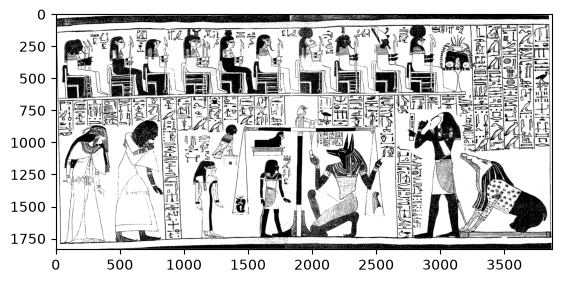

In [4]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage.io
def binarize(img_file, func="WOLF", save=False, thicken_lines=False,
             svg_format=False, transparent=False):
    img_file = Path(img_file)
    img = cv2.imread(img_file, cv2.IMREAD_UNCHANGED)
    # Turn transparent parts of PNGs white
    if img.ndim == 3 and img.shape[2] == 4:
        alpha = img[:, :, 3]
        bgr = img[:, :, :3]

        white = np.full_like(bgr, 255)
        img = np.where(alpha[:, :, None] == 0, white, bgr)

    # Convert to flat 2D grayscale, no alpha (doxapy requires single-channel input)
    if img.ndim == 3:
        gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    else:
        gray_img = img
    # binarize 
    binary_image = np.empty(gray_img.shape, gray_img.dtype)
    facsimile = doxapy.Binarization(getattr(doxapy.Binarization.Algorithms, func))
    facsimile.initialize(gray_img)
    facsimile.to_binary(binary_image)

    # Thicken black lines
    if thicken_lines:
        kernel = np.ones((3, 3), np.uint8)
        binary_image = cv2.erode(binary_image, kernel, iterations=1)

    # Make transparent version if requested
    if transparent:
        h, w = binary_image.shape
        output = np.zeros((h, w, 4), dtype=np.uint8)
        output[..., 0:3] = 0
        output[..., 3] = np.where(binary_image == 255, 0, 255)
    else:
        output = binary_image
        
    plt.imshow(binary_image, cmap="gray")

    # Save PNG
    if save:
        output_path = img_file.with_name(f"{img_file.stem}_{func}.png")
        skimage.io.imsave(output_path, output)

    # Save SVG
    if svg_format:
        svg_path = img_file.with_name(f"{img_file.stem}_{func}.svg")
        png_to_svg(output, svg_path)

    return output

# img_file = "/Users/sophial/Desktop/lepsius_todtenbuch (dragged) 2/page_0001.png"
output = binarize(img_file, func="OTSU", save=True, transparent=True, 
                  thicken_lines=False, svg_format=False)

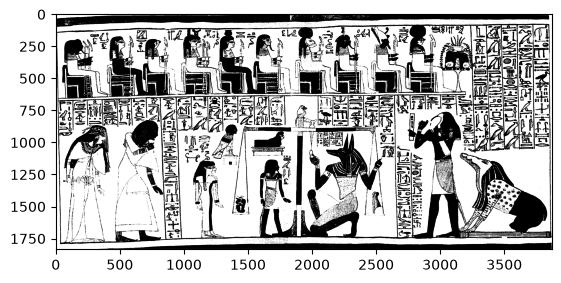

In [5]:
# median filter results
median_filtered = cv2.medianBlur(output, 5)
plt.imshow(median_filtered, cmap="gray")
plt.imshow(output,cmap="gray")

img_file = Path(img_file)
output_path = img_file.with_name(f"{img_file.stem}_{"medfiltered"}.png")
skimage.io.imsave(output_path, output)

In [ ]:
plt.imshow(median_filtered, cmap="gray")
plt.imshow(output,cmap="gray")

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(8, 10))
axes[0].imshow(median_filtered, cmap="gray")
axes[0].set_title("median_filtered (top)")
axes[0].axis("off")
axes[1].imshow(output, cmap="gray")
axes[1].set_title("output (bottom)")
axes[1].axis("off")
plt.tight_layout()
plt.show()